# Credit Card Default Risk: walkthrough on real data

**Data:** 30,000 real credit card customers of a Taiwanese bank, with six months of bills, payments and repayment
status (April–September 2005), and whether each customer defaulted in October 2005.
Source: Yeh, I. (2009), *Default of Credit Card Clients*, UCI Machine Learning Repository, https://doi.org/10.24432/C55S3H

**Questions:**
1. What does the portfolio look like, and how much is at risk?
2. Who defaults?
3. What behaviour warns us early?
4. Can we score every customer's risk, and how should the bank act on it?

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from run_sql import connect

con = connect()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 120)
sql = lambda f: con.sql((ROOT / "sql" / f).read_text()).df()
chart = lambda n: display(Image(filename=str(ROOT / "images" / f"{n}.png"), width=900))

## 1. Look at the raw file first
The raw Excel file has an extra header row, and its columns are coded (`PAY_0`, `BILL_AMT1` and so on).

In [2]:
raw = pd.read_excel(ROOT / "data/raw/default_of_credit_card_clients.xls", header=1)
print(raw.shape)
raw.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Codes that the source never explains
Education is documented as 1–4, marital status as 1–3, and repayment status as -1 or 1–9. The data contains other values:

In [3]:
print("EDUCATION:", raw["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE: ", raw["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_0 (Sep):", raw["PAY_0"].value_counts().sort_index().to_dict())
print("PAY_2 (Aug):", raw["PAY_2"].value_counts().sort_index().to_dict())

EDUCATION: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE:  {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0 (Sep): {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}
PAY_2 (Aug): {-2: 3782, -1: 6050, 0: 15730, 1: 28, 2: 3927, 3: 326, 4: 99, 5: 25, 6: 12, 7: 20, 8: 1}


Two things stand out:
- `EDUCATION` has 0, 5 and 6, and `MARRIAGE` has 0. None of these are documented.
- Status **1** ("1 month late") appears 3,688 times in September (`PAY_0`), but only 28 times in August.
  The months were clearly recorded differently, so month-to-month comparisons should use **2+ months late** instead.

## 2. Clean it
`src/clean_data.py` fixes or flags each issue and reshapes the data into two tables: one row per customer, and one row per customer per month. Every decision is logged:

In [4]:
pd.read_csv(ROOT / "reports/data_quality.csv")

,issue,rows_affected,action
0,Raw file has a second header row (X1..X23 labels),1,Skipped; used the descriptive header row
1,"Repayment status columns named PAY_0, PAY_2..PAY_6 (no PAY_1)",6,Renamed PAY_0 to PAY_1 so all six months line up
2,Duplicate customer IDs,0,None found; no action
3,Missing values (any column),0,None found; no action
4,"EDUCATION codes 0, 5, 6 are not documented",345,Grouped as 'Unknown'
5,MARRIAGE code 0 is not documented,54,Grouped as 'Unknown'
6,Negative bill amounts (customer overpaid = credit balance),3932,Kept; flagged has_credit_balance = 1; utilization floored at 0
7,Status -2 ('no balance') while the bill is above zero,9425,Kept as reported; noted as a source inconsistency
8,Bill above credit limit (over-limit),8274,Kept; flagged is_over_limit = 1
9,"Status 1 ('1 month late') appears 3,688 times in September but only 34 times in Apr–Aug",3722,"Month-to-month trends use 2+ months late (status >= 2), which is recorded consistently"


In [5]:
for t in ["customers", "statements"]:
    print(t, con.sql(f"SELECT COUNT(*) FROM {t}").fetchall()[0][0])
con.sql("SELECT * FROM statements LIMIT 6").df()

customers 30000


statements 180000


,customer_id,month,bill_amount,payment_amount,repayment_status,credit_limit,status_group,months_late,utilization,is_over_limit,has_credit_balance
0,C00001,2005-04-01,0,0,-2,20000,1. No balance,0,0.00,0,0
1,C00001,2005-05-01,0,0,-2,20000,1. No balance,0,0.00,0,0
2,C00001,2005-06-01,0,0,-1,20000,2. Paid in full,0,0.00,0,0
3,C00001,2005-07-01,689,0,-1,20000,2. Paid in full,0,0.03,0,0
4,C00001,2005-08-01,3102,689,2,20000,4. 1-2 months late,2,0.16,0,0
5,C00001,2005-09-01,3913,0,2,20000,4. 1-2 months late,2,0.20,0,0


## 3. Portfolio overview

In [6]:
sql("01_portfolio_overview.sql").T

,0
customers,"30,000.00"
total_credit_lines_bn,5.02
avg_credit_limit,"167,484.00"
total_balance_bn,1.54
portfolio_utilization_pct,30.60
late_in_september_pct,22.70
default_rate_pct,22.10
balance_of_defaulters_bn,0.32
balance_at_risk_pct,20.90


In [7]:
sql("03_monthly_trend.sql")

,month,total_balance_bn,utilization_pct,payments_bn,paid_in_full_pct,revolving_pct,late_2plus_months_pct
0,2005-04-01,1.17,23.30,0.16,19.10,54.30,10.30
1,2005-05-01,1.21,24.10,0.14,18.50,56.50,9.90
2,2005-06-01,1.30,25.90,0.14,19.00,54.90,11.70
3,2005-07-01,1.41,28.10,0.16,19.80,52.50,14.00
4,2005-08-01,1.48,29.40,0.18,20.20,52.40,14.70
5,2005-09-01,1.54,30.60,0.17,19.00,49.10,10.40


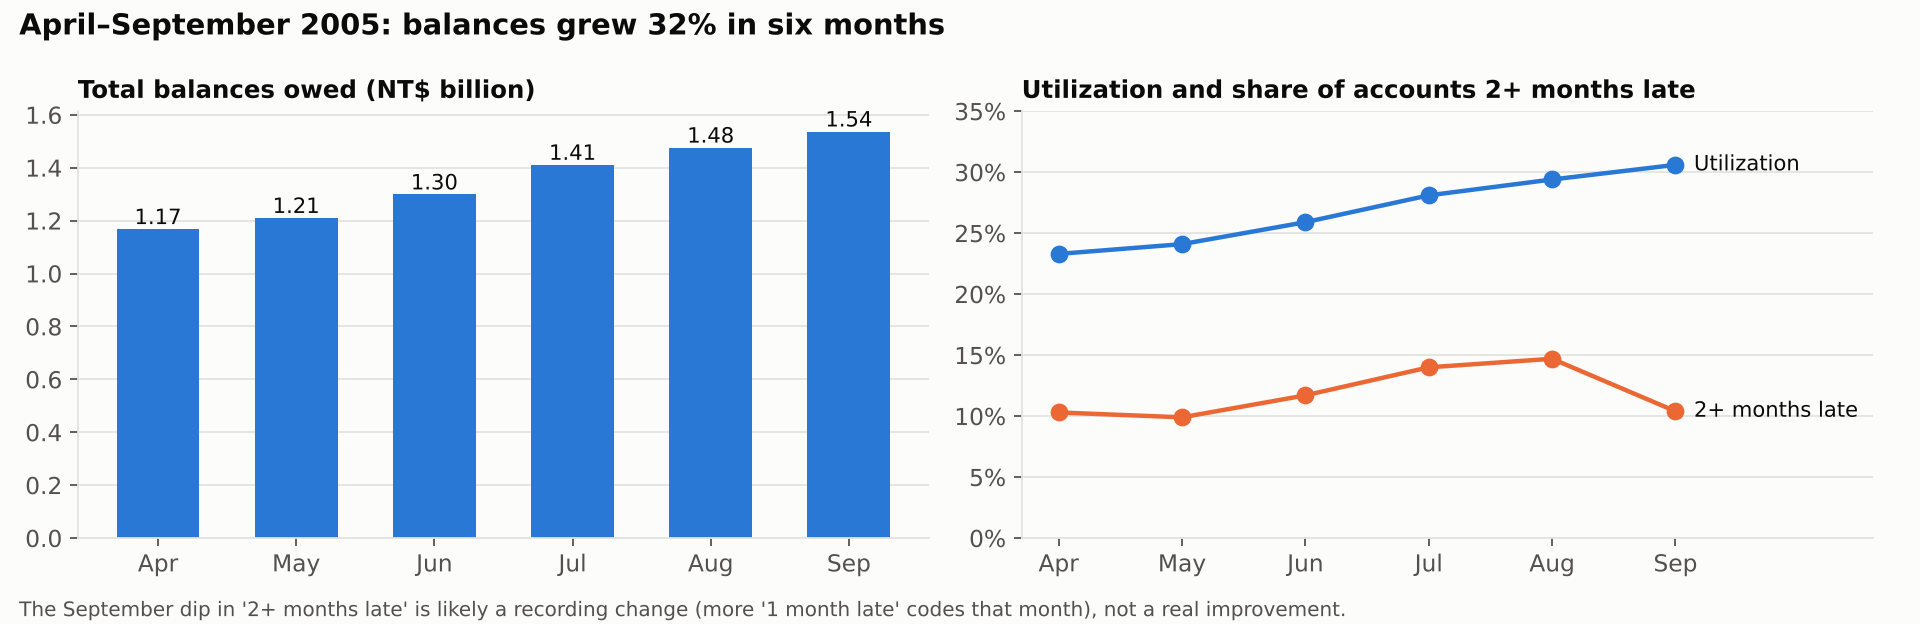

In [8]:
chart("02_monthly_trend")

**What it means:** balances grew **32% in six months** (NT$1.17B → NT$1.54B) and utilization rose from 23% to 31%.
22% of customers defaulted the next month. That's very high, and consistent with Taiwan's 2005–06 card-debt crisis.

## 4. Who defaults?

In [9]:
sql("02_default_by_segment.sql")

,dimension,segment,customers,default_rate_pct,avg_limit
0,Age,1. 21-29,9618,22.80,"124,209.00"
1,Age,2. 30-39,11238,20.30,"197,001.00"
2,Age,3. 40-49,6464,23.00,"180,786.00"
3,Age,4. 50-59,2341,24.90,"163,909.00"
4,Age,5. 60+,339,28.30,"187,847.00"
5,Credit limit (NT$),1. <=50K,7676,31.80,"35,205.00"
6,Credit limit (NT$),2. 50-100K,4822,25.80,"80,759.00"
7,Credit limit (NT$),3. 100-200K,7880,19.50,"158,327.00"
8,Credit limit (NT$),4. 200-400K,7818,15.30,"286,788.00"
9,Credit limit (NT$),5. 400K+,1804,12.00,"485,116.00"


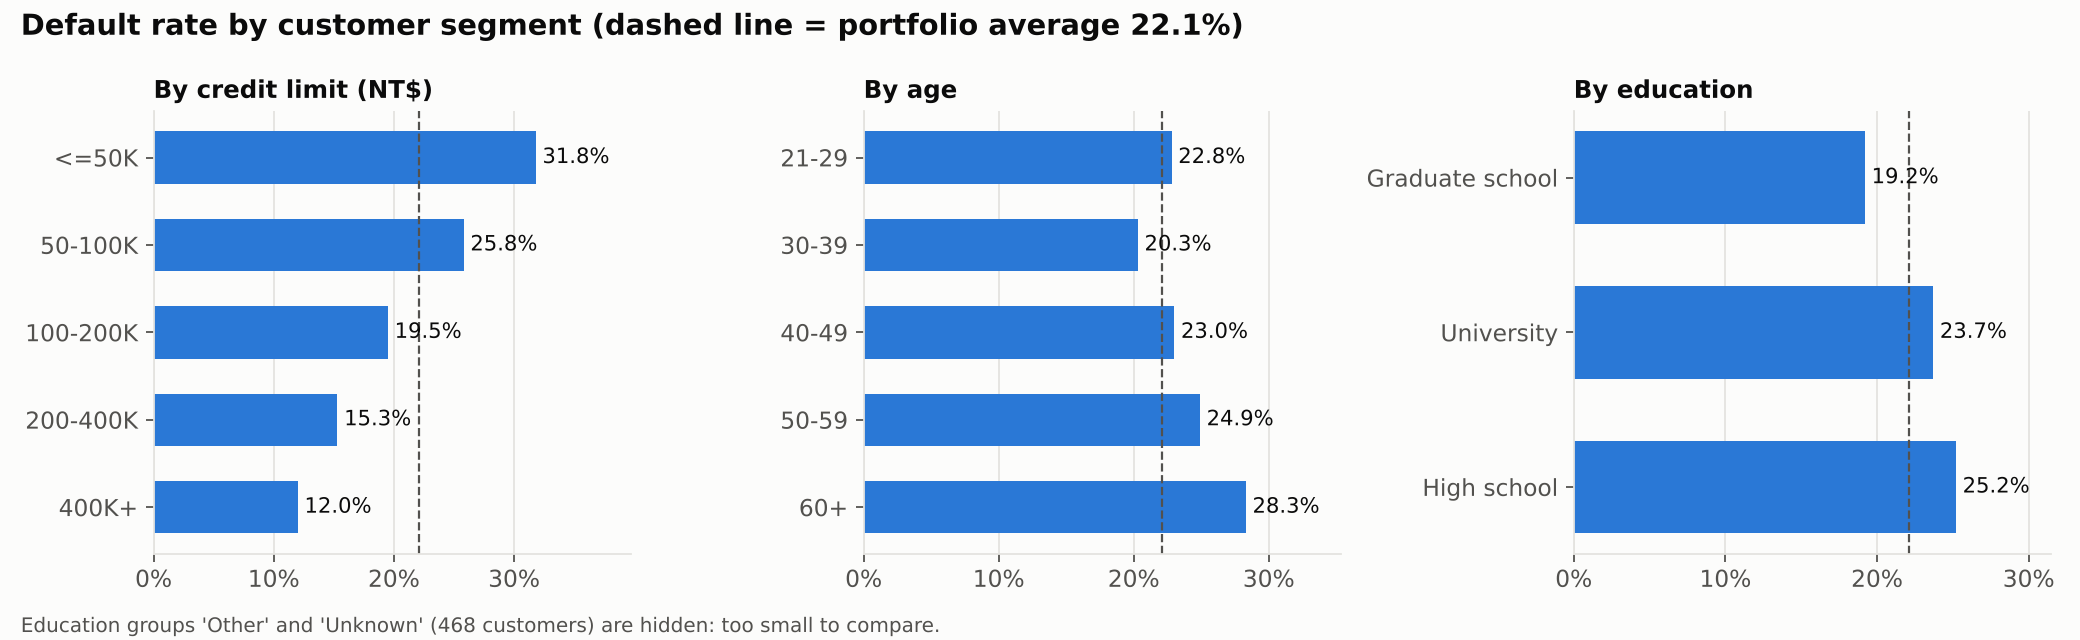

In [10]:
chart("01_default_by_segment")

In [11]:
sql("06_utilization_by_limit.sql").pivot(index="limit_band", columns="utilization_band", values="default_rate_pct")

utilization_band,1. <30%,2. 30-70%,3. 70-90%,4. 90%+
limit_band,,,,
1. <=50K,30.80,35.20,33.90,28.60
2. 50-100K,23.20,27.60,27.10,26.80
3. 100-200K,18.00,19.00,24.00,22.50
4. 200-400K,14.80,11.70,17.30,24.10
5. 400K+,10.60,10.50,17.60,28.30


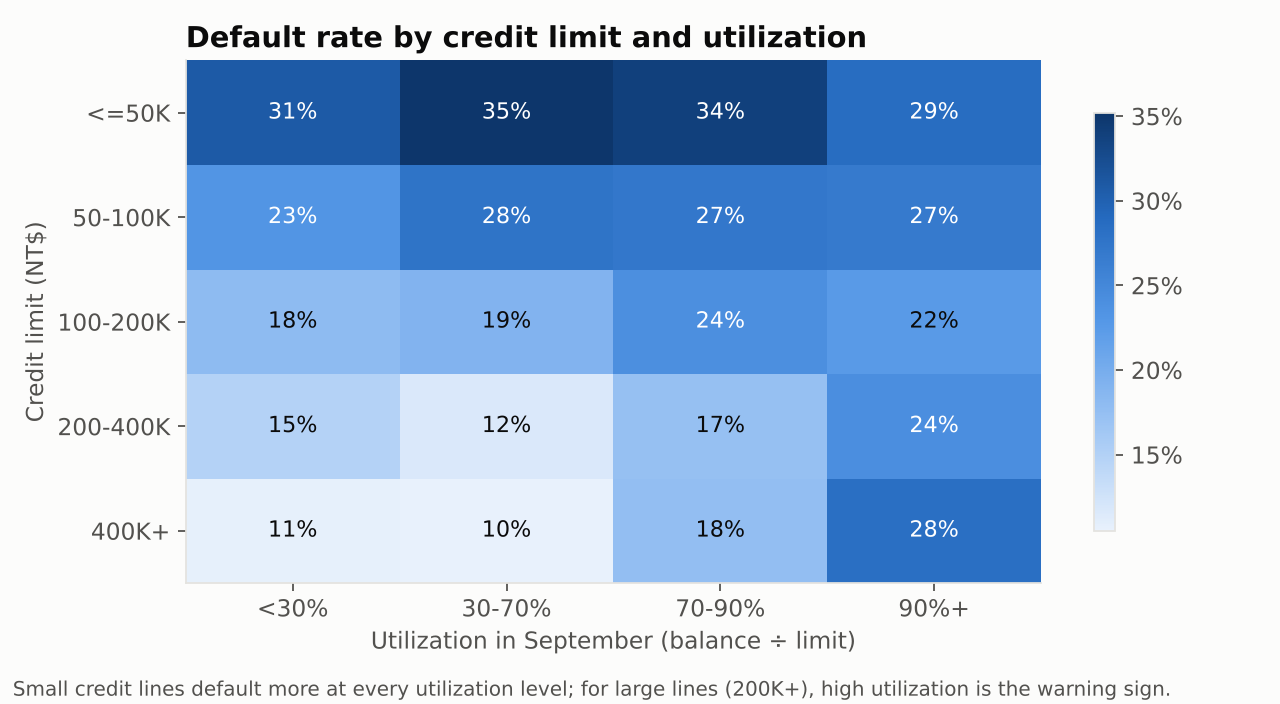

In [12]:
chart("05_utilization_by_limit")

**What it means:** the size of the credit line is the clearest profile signal: 32% default at NT$50K or less, compared with 12% above NT$400K.
Demographic differences are small. For large lines, high utilization nearly doubles the risk.

## 5. Early warning signs

In [13]:
sql("05_early_warning.sql")

,signal,value,customers,default_rate_pct
0,Late months (of last 6),0 months,19931,11.70
1,Late months (of last 6),1 month,4426,29.80
2,Late months (of last 6),2 months,1899,38.80
3,Late months (of last 6),3 months,1154,50.90
4,Late months (of last 6),4-6 months,2590,64.10
5,Payment behaviour,1. Pays in full,5012,12.50
6,Payment behaviour,2. Partial payer,6221,10.60
7,Payment behaviour,3. Minimum payer,8373,11.20
8,Payment behaviour,4. Behind on payments,9528,43.00
9,Payment behaviour,5. Inactive,866,36.60


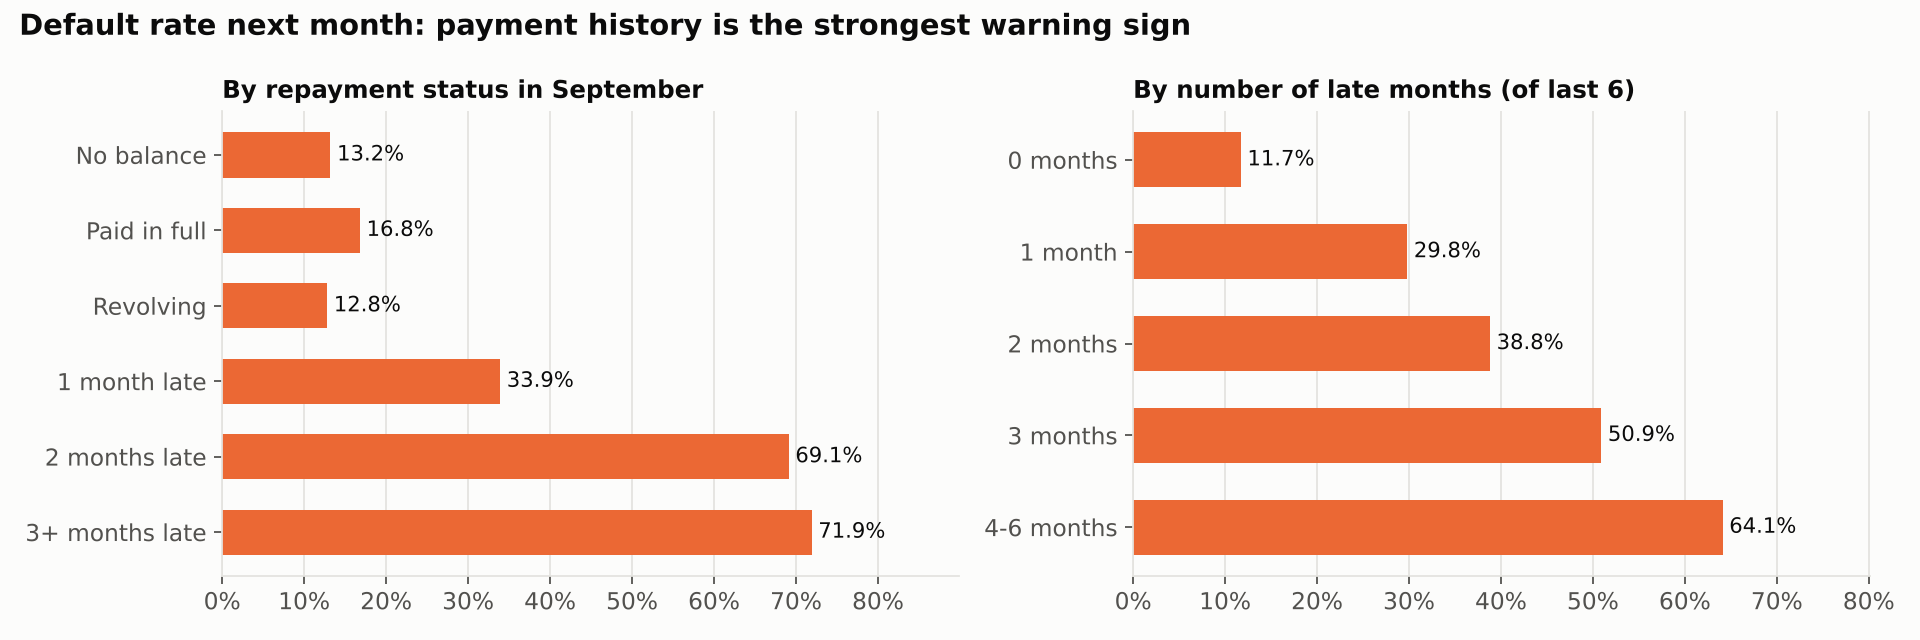

In [14]:
chart("03_early_warning")

In [15]:
sql("04_roll_rates.sql")

,from_status,account_months,to_no_balance_pct,to_paid_in_full_pct,to_revolving_pct,to_1_2_late_pct,to_3plus_late_pct
0,1. No balance,21656,81.30,6.80,5.00,6.90,0.00
1,2. Paid in full,28954,6.60,75.70,12.00,5.70,0.00
2,3. Revolving,81182,0.00,5.10,88.90,6.10,0.00
3,4. 1-2 months late,16331,0.10,8.00,17.20,68.40,6.30
4,5. 3+ months late,1877,0.00,5.10,5.50,36.30,53.10


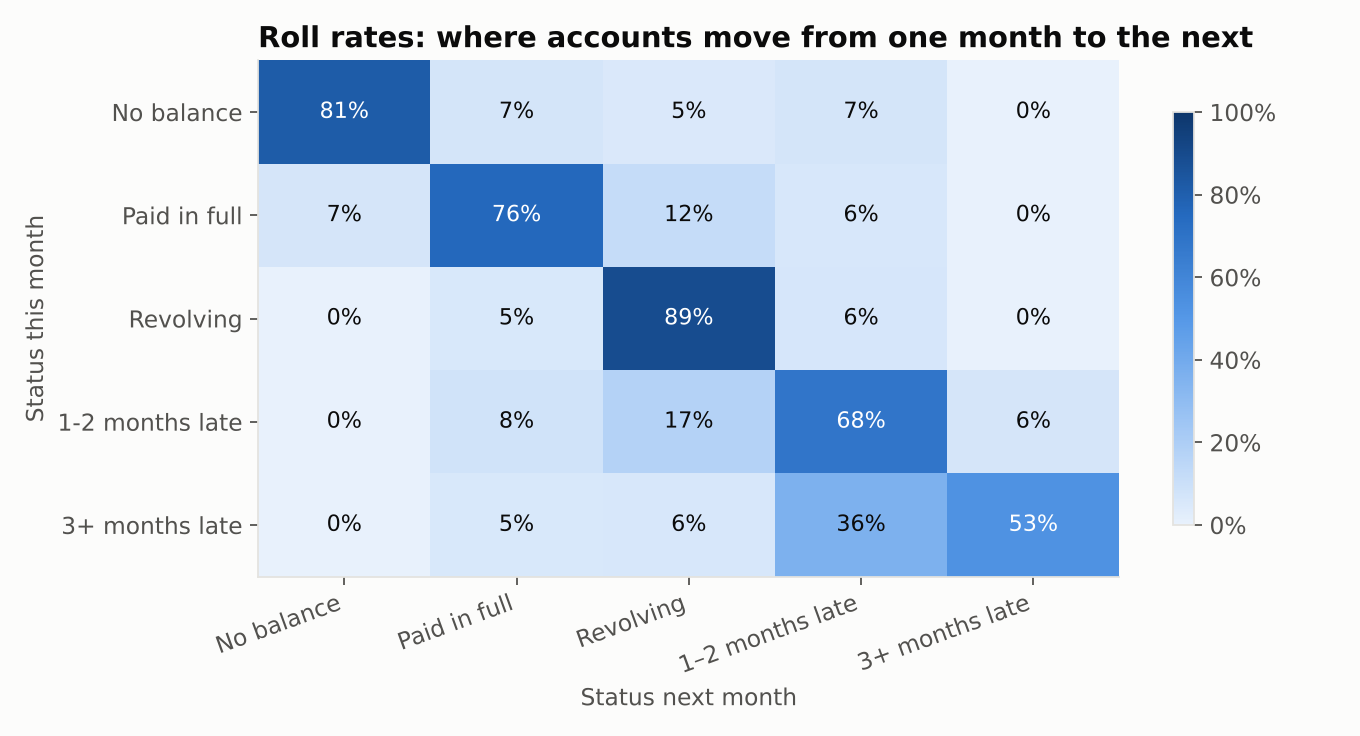

In [16]:
chart("04_roll_rates")

In [17]:
sql("07_payment_behaviour.sql")

,payment_behaviour,customers,pct_customers,default_rate_pct,balance_m,pct_of_balances,pct_of_defaulted_balances,avg_limit
0,1. Pays in full,5012,16.70,12.50,41.10,2.70,1.20,"231,650.00"
1,2. Partial payer,6221,20.70,10.60,222.00,14.40,6.10,"188,542.00"
2,3. Minimum payer,8373,27.90,11.20,850.50,55.30,29.30,"158,021.00"
3,4. Behind on payments,9528,31.80,43.00,423.80,27.60,63.50,"124,191.00"
4,5. Inactive,866,2.90,36.60,0.00,0.00,0.00,"212,679.00"


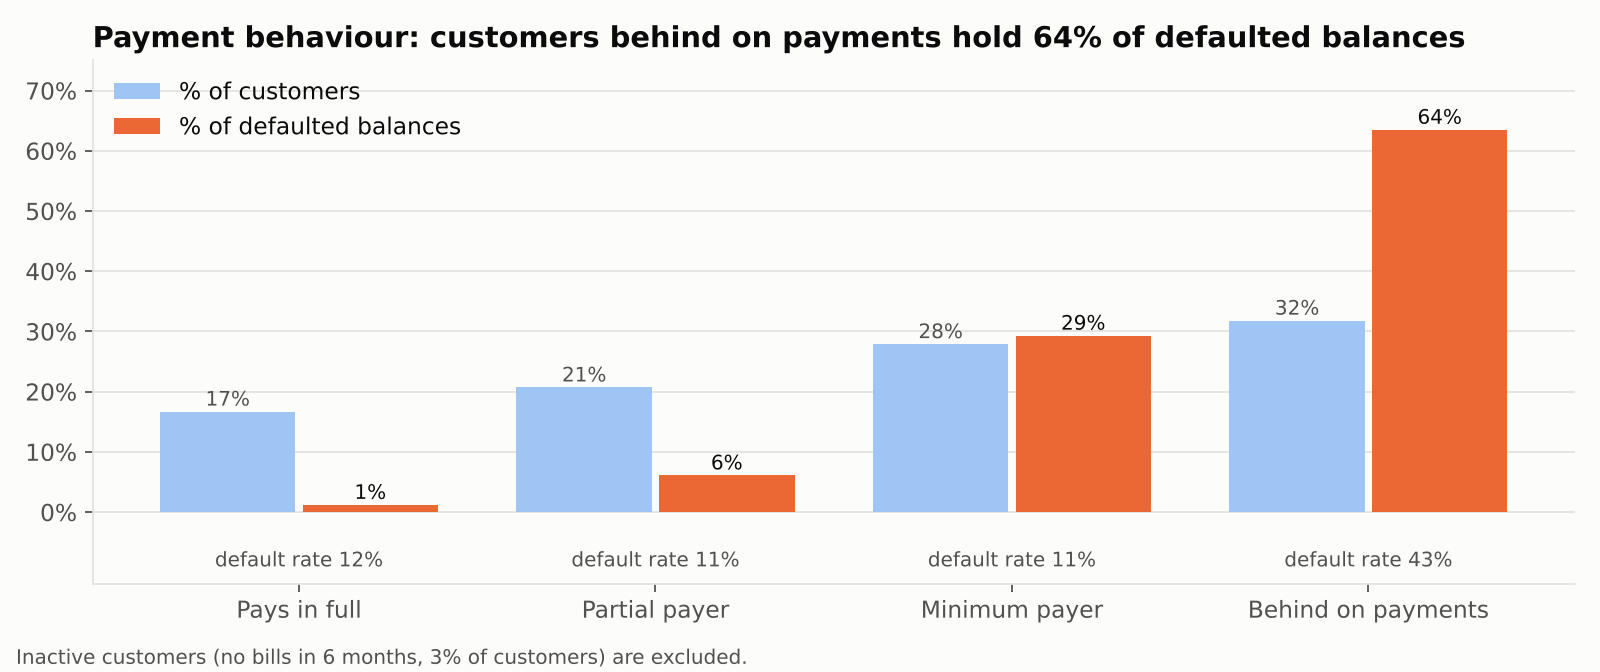

In [18]:
chart("06_payment_behaviour")

**What it means:** payment history beats everything else. One month late takes default risk from about 13% to 34%, and two months late takes it to 69%.
Customers behind on payments are 32% of customers but hold nearly two-thirds of defaulted balances.

**A surprise worth flagging:** customers who pay in full defaulted *slightly more often* (12.5%) than minimum payers (11.2%).
Real data doesn't always match the textbook. I report it rather than hide it.

## 6. Risk score (behaviour-only logistic regression)
Trained on 70% of customers and tested on the 30% it never saw. Demographics are deliberately excluded.

In [19]:
pd.read_csv(ROOT / "reports/results/model_metrics.csv")

,metric,value,meaning
0,AUC (test set),0.75,"0.5 = coin flip, 1.0 = perfect ranking of risky vs safe customers"
1,Gini (test set),0.51,2 x AUC - 1; common in bank credit scoring
2,KS (test set),0.40,max separation between defaulters and non-defaulters
3,AUC (5-fold CV mean),0.76,average over 5 different splits (range 0.755–0.774)
4,Train customers,"21,000.00",70% of customers
5,Test customers,"9,000.00","30% held out, never seen in training"
6,Default rate,0.22,share of customers who defaulted


In [20]:
pd.read_csv(ROOT / "reports/results/model_factors.csv")

,factor,coefficient,odds_multiplier,type
0,Months late in September,0.44,1.55,per 1 std. dev. increase
1,Number of late months (of 6),0.34,1.40,per 1 std. dev. increase
2,Worst delay in last 6 months (months),0.23,1.26,per 1 std. dev. increase
3,Credit limit (log),-0.21,0.81,per 1 std. dev. increase
4,No bills in 6 months (inactive),0.14,1.15,per 1 std. dev. increase
5,Utilization in September,0.07,1.07,per 1 std. dev. increase
6,Share of bills paid (last 5 months),0.07,1.07,per 1 std. dev. increase


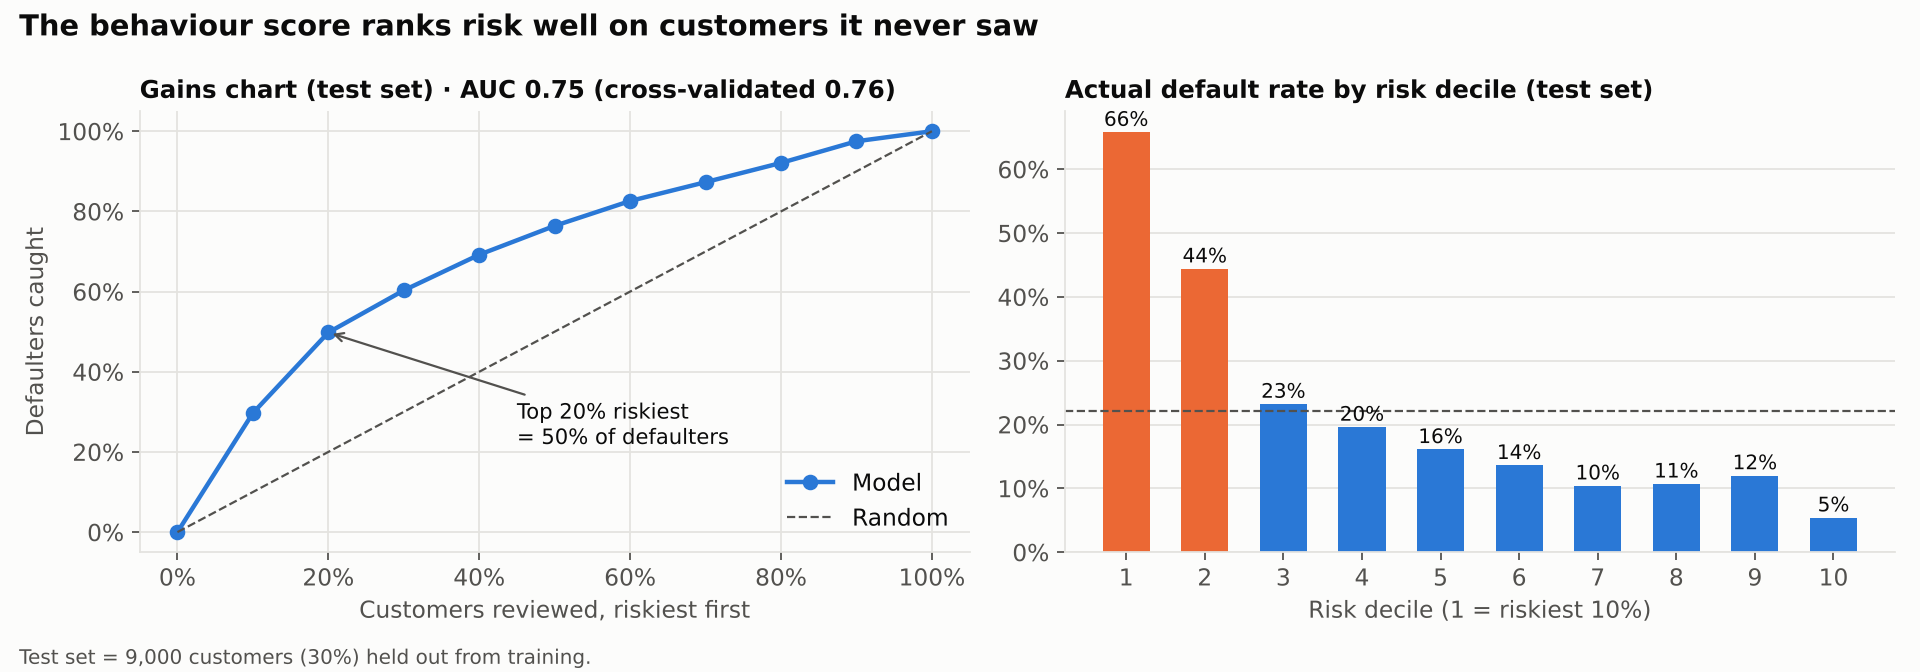

In [21]:
chart("07_model_performance")

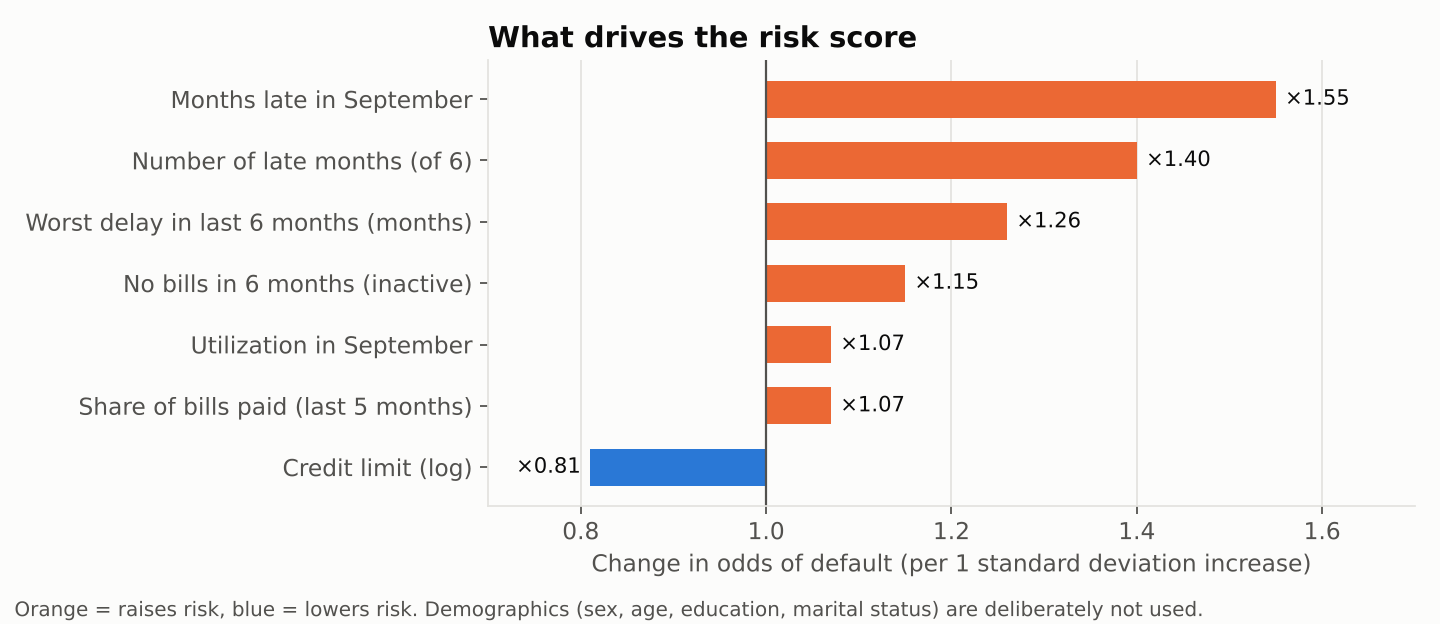

In [22]:
chart("08_model_factors")

In [23]:
sql("09_risk_tiers.sql")

,risk_tier,customers,pct_customers,predicted_default_pct,actual_default_pct,balance_m,pct_of_all_defaulters,pct_of_defaulted_balance
0,1. Low,5262,17.50,9.20,7.30,399.50,5.80,10.30
1,2. Medium,17187,57.30,13.90,14.50,810.80,37.50,31.90
2,3. High,4197,14.00,36.70,36.80,164.60,23.30,23.70
3,4. Very high,3354,11.20,65.90,66.20,162.40,33.50,34.10


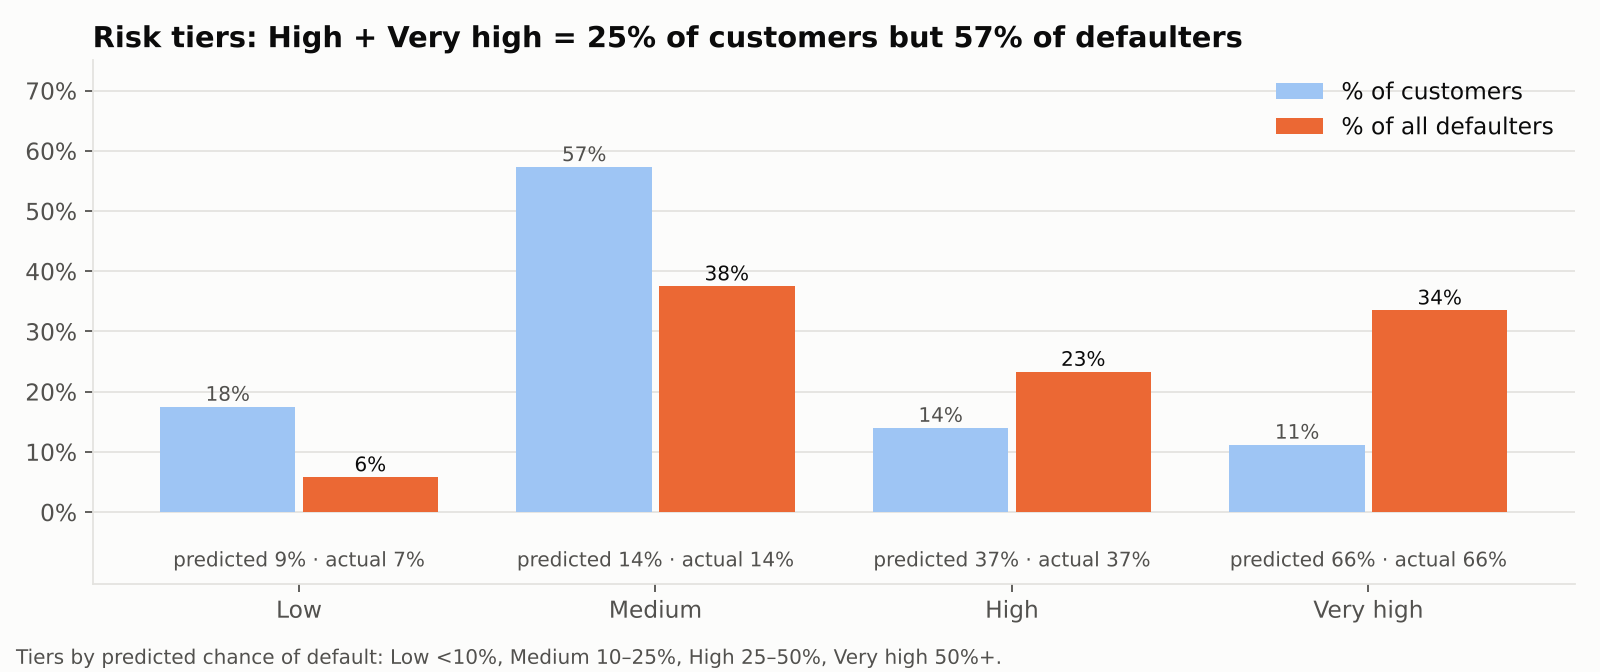

In [24]:
chart("09_risk_tiers")

In [25]:
sql("10_tier_actions.sql")

,risk_tier,customers,avg_limit,avg_utilization_pct,late_in_sept_pct,avg_late_months,suggested_action
0,1. Low,5262,"356,646.00",21.00,0.00,0.00,Eligible for credit-line increases and retention offers
1,2. Medium,17187,"137,404.00",45.00,3.00,0.20,Monitor monthly; payment reminders before due date
2,3. High,4197,"125,038.00",41.00,70.00,1.90,Freeze line increases; proactive outreach and payment plans
3,4. Very high,3354,"77,971.00",65.00,99.00,4.30,Reduce available credit; early collections contact


**What it means:** the score ranks risk well (AUC about 0.76 across 5-fold cross-validation). The riskiest 20% of customers contain about half of all defaulters,
and predicted default rates match actual ones closely in every tier. A bank could use the tiers to decide who gets
credit-line increases, reminders, outreach or reduced limits.

## 7. Limitations
- Only six months of history, so no long-term trends or seasonality.
- No transaction or fraud data (banks don't publish it).
- Status codes -2 and 0 are undocumented; I used the common interpretation.
- 866 customers had no bills for six months, yet 37% are marked as defaulting. I'd raise this with the data owner.